In [2]:
import pandas as pd

## Step 1: Prepare the features

In [7]:
from sklearn.model_selection import train_test_split

# Star with data that contain target
model_df=pd.read_csv("C:\\Users\\Dell\\Desktop\\Titanic Survival Analysis\\Data for analysis\\titanic.csv")

In [8]:
if "Survived" not in model_df.columns:
    raise ValueError("This datset has no Survived column.Use a labeled dataset")

#Create family-related features
if {"SibSp","Parch"}.issubset(model_df.columns):
    model_df["FamilySize"]=(model_df["SibSp"] + model_df["Parch"] + 1)
    model_df["IsAlone"]=(model_df["FamilySize"]==1).astype(int)



In [9]:
# Select useful available columns
candidates = [
    "Pclass", "Sex", "Age", "Fare",
    "Embarked", "SibSp", "Parch",
    "FamilySize", "IsAlone"
]

features = [c for c in candidates if c in model_df.columns]

X = model_df[features]
y = model_df["Survived"]

# Remove rows with missing target labels, if any
valid = y.notna()
X = X.loc[valid]
y = y.loc[valid].astype(int)

print("Features:", features)
print("X shape:", X.shape)
print("Target distribution:")
print(y.value_counts())

Features: ['Pclass', 'Sex', 'Age', 'Fare', 'Embarked', 'SibSp', 'Parch', 'FamilySize', 'IsAlone']
X shape: (891, 9)
Target distribution:
Survived
0    549
1    342
Name: count, dtype: int64


## Step 2:Split training and teting data

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 712
Testing rows: 179


## Step 3: Haandling missing values and categorical columns

In [13]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression

In [15]:
numeric_features = X_train.select_dtypes(include="number").columns.tolist()

print(numeric_features)

['Pclass', 'Age', 'Fare', 'SibSp', 'Parch', 'FamilySize', 'IsAlone']


In [16]:
categorical_features = X_train.select_dtypes(exclude="number").columns.tolist()

print(categorical_features)

['Sex', 'Embarked']


In [19]:
numeric_pipeline=Pipeline([("imputer",SimpleImputer(strategy="median")),
                          ("scaler",StandardScaler())
                          ])


In [21]:
categorical_pipeline=Pipeline([("imputer",SimpleImputer(strategy="most_frequent")),
                          ("encoder",OneHotEncoder(handle_unknown="ignore"))
                          ])


In [22]:
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

model.fit(X_train, y_train)

print("Model training completed.")

Model training completed.


## Step 4: Evaluate the Model

In [23]:
from sklearn.metrics import (accuracy_score , classification_report, confusion_matrix)

y_pred=model.predict(X_test)

In [24]:
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.8045

Classification Report:
              precision    recall  f1-score   support

           0       0.82      0.88      0.85       110
           1       0.78      0.68      0.73        69

    accuracy                           0.80       179
   macro avg       0.80      0.78      0.79       179
weighted avg       0.80      0.80      0.80       179

Confusion Matrix:
[[97 13]
 [22 47]]


## Step 5 : Test the Passenger

In [25]:
new_passenger = pd.DataFrame([{
    "Pclass": 1,
    "Sex": "female",
    "Age": 25,
    "Fare": 80,
    "Embarked": "C",
    "SibSp": 0,
    "Parch": 0,
    "FamilySize": 1,
    "IsAlone": 1
}])

# Keep exactly the features used during training
new_passenger = new_passenger[features]

prediction = model.predict(new_passenger)[0]
probability = model.predict_proba(new_passenger)[0, 1]

print(
    "Prediction:",
    "Survived" if prediction == 1 else "Did not survive"
)
print(f"Estimated survival probability: {probability:.2%}")

Prediction: Survived
Estimated survival probability: 94.65%


# Final Visual Report

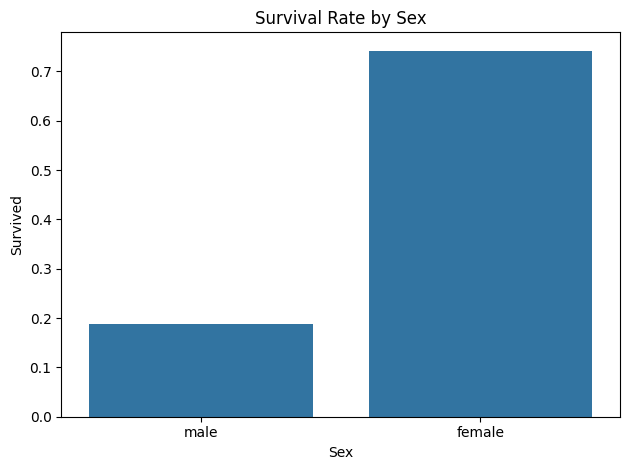

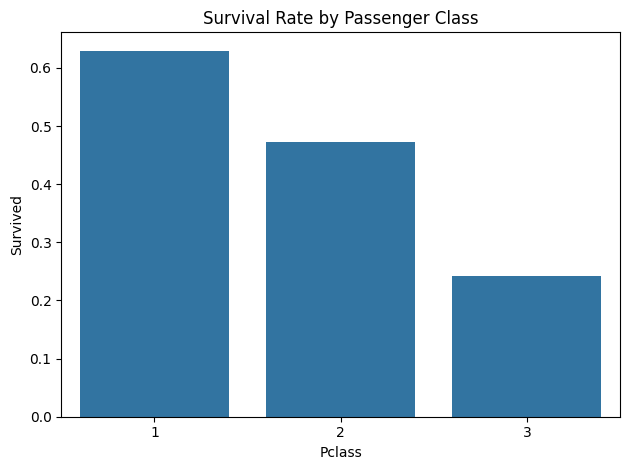

In [27]:
import os
import matplotlib.pyplot as plt
import seaborn as sns

os.makedirs("visualizations", exist_ok=True)

# Survival by sex
sns.barplot(data=model_df, x="Sex", y="Survived", errorbar=None)
plt.title("Survival Rate by Sex")
plt.tight_layout()
plt.savefig("visualizations/survival_by_sex.png", dpi=300)
plt.show()

# Survival by class
sns.barplot(data=model_df, x="Pclass", y="Survived", errorbar=None)
plt.title("Survival Rate by Passenger Class")
plt.tight_layout()
plt.savefig("visualizations/survival_by_class.png", dpi=300)
plt.show()
